## Mammals and Forest Conservation Around Google's Finnish Data Centres

**Project question**: What can publicly available geospatial data reveal about mammal observations, forest clearing, and forest conservation values around Google's planned data centre sites in Finland?

**Background**: In 2026, forest clearing took place in Muhos and Otanmäki (Kajaani), Finland, as part of preparations for Google's planned data centre developments. These land-use changes raise questions about the environmental characteristics of the affected areas and their surrounding landscapes, including their potential relevance to wildlife conservation.

**Project aim**: The analysis examines the spatial distribution of mammal observations from the Global Biodiversity Information Facility (GBIF) for 2016–2025, identifies nearby protected areas and compares forest clearing and forest structural complexity across the selected areas.

In [1]:
# Import libraries

from pathlib import Path

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

from shapely.geometry import Point


In [2]:
# Define project folders

project_folder = Path.cwd().parent
data_folder = project_folder / "data"
output_folder = project_folder / "outputs"

# Create the output folder 
output_folder.mkdir(exist_ok=True)

print("Project folder:", project_folder)
print("Data folder:", data_folder)
print("Output folder:", output_folder)



Project folder: C:\Users\malcfran\Downloads\python_foundation\Finland_Mammal_Conservation
Data folder: C:\Users\malcfran\Downloads\python_foundation\Finland_Mammal_Conservation\data
Output folder: C:\Users\malcfran\Downloads\python_foundation\Finland_Mammal_Conservation\outputs


### 1. Study sites visualization

In [4]:
# Create an interactive map to visulize the study sites of Google data centers in Finland

# Define the study sites and their coordinates

study_sites = pd.DataFrame({
    "Site": ["Kajaani-Otanmaki", "Muhos"],
    "Latitude": [64.1073, 64.8320],
    "Longitude": [27.1576, 26.1080]
})

study_sites


study_map = folium.Map(
    location=[64.5, 26.0],
    zoom_start=6,
    tiles="OpenStreetMap"
)

# Add a marker for each study site
for index, row in study_sites.iterrows():

    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=row["Site"],
        tooltip=row["Site"]
    ).add_to(study_map)

# Display the map
study_map


## 2. Mammal occurences analaysis 

In [5]:
#Load the mammals occurences (only presence data) from GBIF website
kajaani_mammals=pd.read_csv(data_folder/"Kajaani_mammals.csv", sep="\t",low_memory=False)
muhos_mammals=pd.read_csv(data_folder/"Muhos_mammals.csv", sep="\t",low_memory=False)

print("Kajaani records:", len(kajaani_mammals))
print("Muhos records:", len(muhos_mammals))


Kajaani records: 1406
Muhos records: 811


In [6]:
# Keep only mammal observations from 2016 to 2025

kajaani_filtered = kajaani_mammals[
    kajaani_mammals["year"].between(2016, 2025)
].copy()

muhos_filtered = muhos_mammals[
    muhos_mammals["year"].between(2016, 2025)
].copy()

print("Kajaani:", len(kajaani_filtered), "records")
print("Muhos:", len(muhos_filtered), "records")


Kajaani: 616 records
Muhos: 811 records


In [7]:
#which mammal species we have from 2016 to 2025
print("kajaani-Number of species:",kajaani_filtered["species"].nunique())
print(kajaani_filtered["species"].value_counts())

print("Muhos-Number of species:", muhos_filtered["species"].nunique())
print(muhos_filtered["species"].value_counts())


      

kajaani-Number of species: 25
species
Sciurus vulgaris            213
Pteromys volans             200
Erinaceus europaeus          44
Lepus timidus                23
Lepus europaeus              20
Capreolus capreolus          15
Lutra lutra                  13
Rangifer tarandus            11
Neogale vison                11
Myotis mystacinus             7
Eptesicus nilssonii           7
Castor canadensis             5
Vulpes vulpes                 5
Ondatra zibethicus            4
Alces alces                   4
Nyctereutes procyonoides      3
Lynx lynx                     2
Gulo gulo                     2
Myotis daubentonii            2
Odocoileus virginianus        2
Mustela putorius              2
Canis lupus                   1
Martes martes                 1
Ursus arctos                  1
Myodes glareolus              1
Name: count, dtype: int64
Muhos-Number of species: 30
species
Sciurus vulgaris            276
Erinaceus europaeus         113
Lepus europaeus              90
Epte

In [8]:
#convert the mammals occurences in geodataframe
kajaani_gdf=gpd.GeoDataFrame(kajaani_filtered,geometry=gpd.points_from_xy(kajaani_filtered["decimalLongitude"],
                                                                         kajaani_filtered["decimalLatitude"]),
                                 crs="EPSG:4326")


muhos_gdf=gpd.GeoDataFrame(muhos_filtered,geometry=gpd.points_from_xy(muhos_filtered["decimalLongitude"],
                                                                    muhos_filtered["decimalLatitude"]),
                                                                    crs="4326")
print("Kajaani CRS:",kajaani_gdf.crs)
print("Muhos CRS:",muhos_gdf.crs)


Kajaani CRS: EPSG:4326
Muhos CRS: EPSG:4326


In [9]:
# Visualize GBIF mammal occurrences (2016-2025)

occurrence_map = folium.Map(
    location=[64.5, 26.5],
    zoom_start=7,
    tiles="OpenStreetMap"
)

# Add Kajaani mammal observations
kajaani_layer = folium.FeatureGroup(name="Kajaani GBIF records")

for index, row in kajaani_gdf.iterrows():
    folium.CircleMarker(
        location=[row["decimalLatitude"], row["decimalLongitude"]],
        radius=2,
        color="blue",
        fill=True,
        fill_opacity=0.5
    ).add_to(kajaani_layer)

kajaani_layer.add_to(occurrence_map)

# Add Muhos mammal observations
muhos_layer = folium.FeatureGroup(name="Muhos GBIF records")

for index, row in muhos_gdf.iterrows():
    folium.CircleMarker(
        location=[row["decimalLatitude"], row["decimalLongitude"]],
        radius=2,
        color="orange",
        fill=True,
        fill_opacity=0.5
    ).add_to(muhos_layer)

muhos_layer.add_to(occurrence_map)

# Add provisional study site locations
for index, row in study_sites.iterrows():
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=row["Site"]
    ).add_to(occurrence_map)

# Add layer control
folium.LayerControl().add_to(occurrence_map)

occurrence_map


The map displays georeferenced mammal occurrence records obtained from GBIF. The spatial distribution of records may reflect differences in observation effort and data availability and should not be interpreted as a direct measure of mammal abundance.


In [10]:
#reproject mammal observations to the finnish coordinates system
kajaani_3067=kajaani_gdf.to_crs("EPSG:3067")
muhos_3067=muhos_gdf.to_crs("EPSG:3067")
#convert study sites into a geodataframe

sites_gdf=gpd.GeoDataFrame(study_sites,
                           geometry=gpd.points_from_xy(study_sites["Longitude"],
                                                       study_sites["Latitude"]
    ),
    crs="EPSG:4326"
)

# Reproject study sites to EPSG:3067
sites_3067 = sites_gdf.to_crs("EPSG:3067")

print("Mammal observations:", kajaani_3067.crs)
print("Study sites:", sites_3067.crs)


Mammal observations: EPSG:3067
Study sites: EPSG:3067


To investigate mammal occurrence records around the proposed Google data centre sites in Kajaani–Otanmäki and Muhos, three spatial buffers of 5, 10 and 25 km were created around each provisional reference point.
Using multiple buffer sizes allows us to examine how the number of recorded species, occurrence records and overlap with protected areas change with spatial scale.
The buffers are cumulative, meaning that the 10 km buffer includes the 5 km area, and the 25 km buffer includes both smaller areas.

In [11]:
# Create 5, 10 and 25 km buffers around the study sites

buffer_distances = [5000, 10000, 25000]

buffers = []

for distance in buffer_distances:
    buffer = sites_3067.copy()
    buffer["geometry"] = buffer.geometry.buffer(distance)
    buffer["Buffer_km"] = distance / 1000
    buffers.append(buffer)

# Combine all buffers into one GeoDataFrame
buffers_gdf = pd.concat(buffers, ignore_index=True)

# Display the results
buffers_gdf[["Site", "Buffer_km", "geometry"]]


,Site,Buffer_km,geometry
0,Kajaani-Otanmaki,5.0,"POLYGON ((512678.978 7108980.487, 512654.902 7..."
1,Muhos,5.0,"POLYGON ((462673.354 7190029.735, 462649.277 7..."
2,Kajaani-Otanmaki,10.0,"POLYGON ((517678.978 7108980.487, 517630.825 7..."
3,Muhos,10.0,"POLYGON ((467673.354 7190029.735, 467625.201 7..."
4,Kajaani-Otanmaki,25.0,"POLYGON ((532678.978 7108980.487, 532558.596 7..."
5,Muhos,25.0,"POLYGON ((482673.354 7190029.735, 482552.972 7..."


In [12]:
# Visualize study sites and spatial buffers

buffer_map = folium.Map(
    location=[64.5, 26.5],
    zoom_start=7,
    tiles="OpenStreetMap"
)

# Add satellite imagery as an optional basemap
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Satellite",
    overlay=False
).add_to(buffer_map)

# Define buffer colors
buffer_colors = {
    5: "#D95D39",    # Terracotta
    10: "#9C4D8E",   # Orchid
    25: "#008C95"    # Teal
}

# Add buffers to the map
for distance, color in buffer_colors.items():

    layer = folium.FeatureGroup(name=f"{distance} km buffer")

    selected_buffers = buffers_gdf[
        buffers_gdf["Buffer_km"] == distance
    ].to_crs("EPSG:4326")

    folium.GeoJson(
        selected_buffers,
        style_function=lambda feature, c=color: {
            "color": c,
            "weight": 3,
            "fillOpacity": 0.05
        }
    ).add_to(layer)

    layer.add_to(buffer_map)

# Add provisional study sites
for index, row in study_sites.iterrows():

    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=row["Site"],
        tooltip=row["Site"]
    ).add_to(buffer_map)

# Add layer control
folium.LayerControl().add_to(buffer_map)

# Display map
buffer_map


In [13]:
# Count mammal records and species within each buffer

results = []

for site, mammals in [("Kajaani-Otanmaki", kajaani_3067),
                      ("Muhos", muhos_3067)]:

    for distance in [5, 10, 25]:

        buffer = buffers_gdf[
            (buffers_gdf["Site"] == site) &
            (buffers_gdf["Buffer_km"] == distance)
        ].geometry.iloc[0]

        inside = mammals[mammals.within(buffer)]

        results.append([site, distance, len(inside), inside["species"].nunique()])

buffer_results = pd.DataFrame(
    results,
    columns=["Site", "Buffer_km", "Records", "Species"]
)

buffer_results



,Site,Buffer_km,Records,Species
0,Kajaani-Otanmaki,5,23,8
1,Kajaani-Otanmaki,10,26,9
2,Kajaani-Otanmaki,25,114,17
3,Muhos,5,12,5
4,Muhos,10,36,11
5,Muhos,25,252,24


Mammal occurrence records were spatially filtered using the 5, 10 and 25 km buffers. For each site and buffer, the total number of GBIF records and the number of distinct mammal species were calculated. Because the buffers are cumulative, records within smaller buffers are also included in the larger ones.

In [14]:
# Identify mammal species recorded within each buffer


species_results = []

for site, mammals in [("Kajaani-Otanmaki", kajaani_3067),
                      ("Muhos", muhos_3067)]:

    for distance in [5, 10, 25]:

        # Select buffer
        buffer = buffers_gdf[
            (buffers_gdf["Site"] == site) &
            (buffers_gdf["Buffer_km"] == distance)
        ].geometry.iloc[0]

        # Select mammal records within buffer
        inside = mammals[mammals.within(buffer)]

        # Count records for each species
        species_counts = inside["species"].value_counts()

        for species, count in species_counts.items():
            species_results.append([site, distance, species, count])

# Create results table
species_by_buffer = pd.DataFrame(
    species_results,
    columns=["Site", "Buffer_km", "Species", "Records"]
)

species_by_buffer


,Site,Buffer_km,Species,Records
0,Kajaani-Otanmaki,5,Sciurus vulgaris,13
1,Kajaani-Otanmaki,5,Capreolus capreolus,4
2,Kajaani-Otanmaki,5,Lutra lutra,1
3,Kajaani-Otanmaki,5,Lepus timidus,1
4,Kajaani-Otanmaki,5,Neogale vison,1
...,...,...,...,...
69,Muhos,25,Meles meles,1
70,Muhos,25,Sicista betulina,1
71,Muhos,25,Martes martes,1
72,Muhos,25,Sorex araneus,1


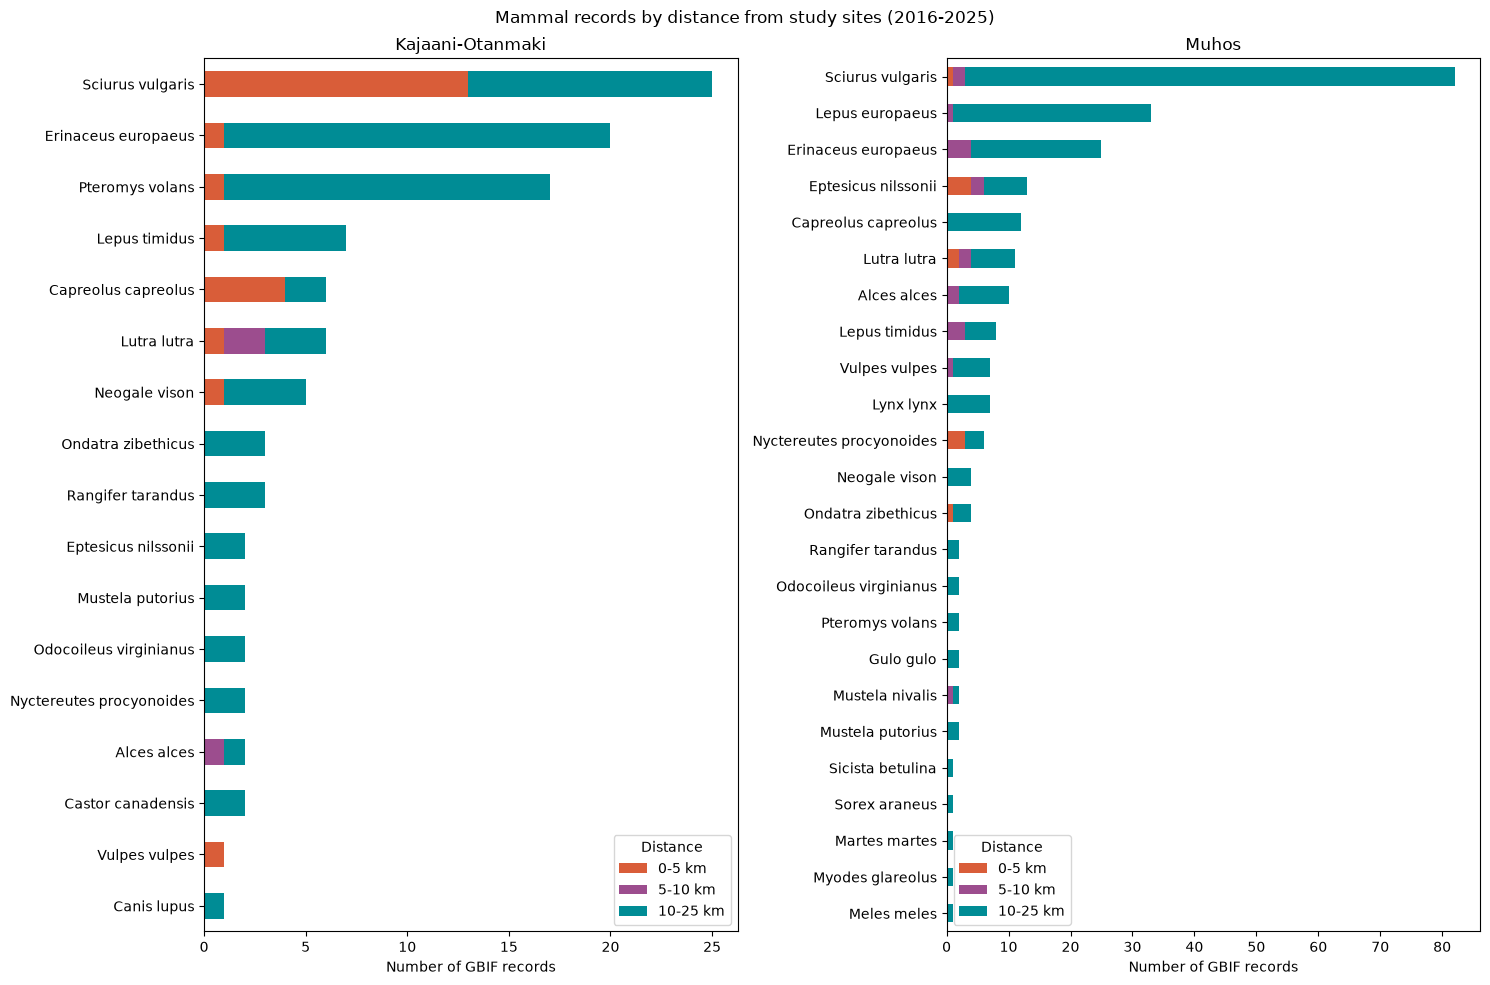

In [15]:
# Mammal records by species and distance from each study site

fig, axes = plt.subplots(1, 2, figsize=(15, 10))

for ax, site in zip(axes, ["Kajaani-Otanmaki", "Muhos"]):

    # Select site data
    data = species_by_buffer[
        species_by_buffer["Site"] == site
    ]

    # Records within cumulative buffers
    counts = data.pivot_table(
        index="Species",
        columns="Buffer_km",
        values="Records",
        fill_value=0
    ).reindex(columns=[5, 10, 25], fill_value=0)

    # Convert into non-overlapping distance bands
    bands = pd.DataFrame({
        "0-5 km": counts[5],
        "5-10 km": counts[10] - counts[5],
        "10-25 km": counts[25] - counts[10]
    })

    # Sort species by total records
    bands = bands.loc[bands.sum(axis=1).sort_values().index]

    # Plot stacked horizontal bars
    bands.plot(
        kind="barh",
        stacked=True,
        ax=ax,
        color=["#D95D39", "#9C4D8E", "#008C95"]
    )

    ax.set_title(site)
    ax.set_xlabel("Number of GBIF records")
    ax.set_ylabel("")
    ax.legend(title="Distance")

plt.suptitle("Mammal records by distance from study sites (2016-2025)")
plt.tight_layout()

plt.savefig(
    output_folder / "mammal_records_by_distance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


**Mammal occurrence records by distance from the planned Google data centre sites in Kajaani–Otanmäki and Muhos, Finland.** Horizontal stacked bars show the number of GBIF mammal records documented between 2016 and 2025 within three non-overlapping distance bands (0–5, 5–10 and 10–25 km) around each site. The bars illustrate the distribution of species records across the surrounding landscapes. Differences in the number of records may reflect both species occurrence and variation in observation effort.

In [16]:
# Identify the most frequently recorded species in each buffer

top_species = species_by_buffer[
    species_by_buffer["Records"] ==
    species_by_buffer.groupby(
        ["Site", "Buffer_km"]
    )["Records"].transform("max")
]

top_species = top_species.sort_values(
    ["Site", "Buffer_km"]
).reset_index(drop=True)

top_species

,Site,Buffer_km,Species,Records
0,Kajaani-Otanmaki,5,Sciurus vulgaris,13
1,Kajaani-Otanmaki,10,Sciurus vulgaris,13
2,Kajaani-Otanmaki,25,Sciurus vulgaris,25
3,Muhos,5,Eptesicus nilssonii,4
4,Muhos,10,Eptesicus nilssonii,6
5,Muhos,25,Sciurus vulgaris,82


## 3. Natura 2000 Sites Around the Study Areas

To provide a broader conservation context, Natura 2000 sites were mapped within 25 km of the two planned data centre locations using spatial data from the Finnish Environment Institute (SYKE).

The distance from each provisional site location to the nearest Natura 2000 area was also calculated. This provides a simple measure of proximity to conservation-designated land, without implying direct ecological impacts from the planned developments.

In [21]:
# Load Natura 2000 layers from SYKE

natura_sci = gpd.read_file(
    data_folder / "natura.zip",
    layer="natura2000sci_alueet"
)

natura_sac = gpd.read_file(
    data_folder / "natura.zip",
    layer="natura2000sac_alueet"
)

natura_spa = gpd.read_file(
    data_folder / "natura.zip",
    layer="natura2000spa_alueet"
)

# Combine the three layers
natura = gpd.GeoDataFrame(
    pd.concat([
        natura_sci[["geometry"]],
        natura_sac[["geometry"]],
        natura_spa[["geometry"]]
    ], ignore_index=True),
    crs="EPSG:3067"
)

print("Natura 2000 features:", len(natura))

Natura 2000 features: 2102


In [22]:
# Select 25 km buffers
buffers_25 = buffers_gdf[
    buffers_gdf["Buffer_km"] == 25
].copy()

# Clip Natura 2000 sites to the buffers
natura_nearby = gpd.clip(natura, buffers_25)

print("Natura 2000 features within buffers:", len(natura_nearby))

Natura 2000 features within buffers: 32


In [23]:
# Create interactive map
natura_map = folium.Map(
    location=[64.5, 26.5],
    zoom_start=7,
    tiles="OpenStreetMap"
)

# Add 25 km buffers
folium.GeoJson(
    buffers_25.to_crs("EPSG:4326"),
    name="25 km buffers",
    style_function=lambda feature: {
        "color": "orange",
        "weight": 2,
        "fillOpacity": 0.05
    }
).add_to(natura_map)

# Add Natura 2000 areas
folium.GeoJson(
    natura_nearby.to_crs("EPSG:4326"),
    name="Natura 2000",
    style_function=lambda feature: {
        "color": "green",
        "weight": 1,
        "fillColor": "green",
        "fillOpacity": 0.4
    }
).add_to(natura_map)

# Add Google study sites
for index, row in study_sites.iterrows():
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=row["Site"]
    ).add_to(natura_map)

# Add layer control
folium.LayerControl().add_to(natura_map)

natura_map

In [24]:
# Calculate distance to nearest Natura 2000 area

results = []

for index, site in sites_3067.iterrows():

    distance_km = natura.distance(site.geometry).min() / 1000

    results.append([site["Site"], round(distance_km, 2)])

distance_results = pd.DataFrame(
    results,
    columns=["Site", "Nearest_Natura2000_km"]
)

distance_results

,Site,Nearest_Natura2000_km
0,Kajaani-Otanmaki,3.43
1,Muhos,5.66


### 4. Mammal Species of Conservation Interest and Protected Areas

A subset of mammal species of conservation interest was selected from the GBIF records, including the Siberian flying squirrel, Eurasian otter, large carnivores and Finnish forest reindeer.



In [27]:
# Select mammal species of conservation interest

species_info = {
    "Pteromys volans": ("Siberian flying squirrel", "#8E44AD"),
    "Lutra lutra": ("Eurasian otter", "#1F78B4"),
    "Lynx lynx": ("Eurasian lynx", "#E67E22"),
    "Rangifer tarandus fennicus": ("Finnish forest reindeer", "#8C564B"),
    "Gulo gulo": ("Wolverine", "#2C3E50"),
    "Canis lupus": ("Grey wolf", "#C0392B"),
    "Ursus arctos": ("Brown bear", "#64802D")
}

# Combine observations from both study areas
mammals = gpd.GeoDataFrame(
    pd.concat([kajaani_3067, muhos_3067], ignore_index=True),
    geometry="geometry",
    crs="EPSG:3067"
)

# Identify Finnish forest reindeer records
forest_reindeer = (
    (mammals["species"] == "Rangifer tarandus") &
    (
        mammals["infraspecificEpithet"].fillna("").eq("fennicus") |
        mammals["scientificName"].fillna("").str.contains(
            "Rangifer tarandus fennicus", case=False, regex=False
        )
    )
)

# Select species of conservation interest
selected = mammals[
    mammals["species"].isin(species_info.keys()) | forest_reindeer
].copy()

selected["Map_species"] = selected["species"]
selected.loc[
    selected["species"] == "Rangifer tarandus",
    "Map_species"
] = "Rangifer tarandus fennicus"

# Keep observations within 25 km buffers
buffers_25 = buffers_gdf[buffers_gdf["Buffer_km"] == 25].copy()
selected = gpd.clip(selected, buffers_25)

# Check coordinate uncertainty
selected["uncertainty"] = pd.to_numeric(
    selected["coordinateUncertaintyInMeters"],
    errors="coerce"
)

# Exclude records with reported uncertainty above 10 km
selected = selected[
    selected["uncertainty"].isna() |
    (selected["uncertainty"] <= 10000)
].copy()

print(selected["Map_species"].value_counts())

Map_species
Lutra lutra                   17
Pteromys volans               12
Lynx lynx                      7
Rangifer tarandus fennicus     4
Gulo gulo                      2
Name: count, dtype: int64


In [28]:
# Create interactive map
species_map = folium.Map(
    location=[64.5, 26.5],
    zoom_start=7,
    tiles="OpenStreetMap"
)

# Add Natura 2000 areas
folium.GeoJson(
    natura_nearby.to_crs("EPSG:4326"),
    name="Natura 2000",
    style_function=lambda x: {
        "color": "green",
        "weight": 1,
        "fillOpacity": 0.2
    }
).add_to(species_map)

# Add 25 km buffers
folium.GeoJson(
    buffers_25.to_crs("EPSG:4326"),
    name="25 km buffers",
    style_function=lambda x: {
        "color": "gray",
        "weight": 2,
        "fillOpacity": 0
    }
).add_to(species_map)

# Reproject mammal observations for Folium
selected_wgs84 = selected.to_crs("EPSG:4326")

# Add one layer for each species
for species, (name, color) in species_info.items():

    observations = selected_wgs84[
        selected_wgs84["Map_species"] == species
    ]

    layer = folium.FeatureGroup(name=f"{name} ({len(observations)})")

    for _, row in observations.iterrows():

        year = int(row["year"]) if pd.notna(row["year"]) else "Unknown"
        unc = row["uncertainty"]

        # Filled circle if reported uncertainty is <= 1 km
        precise = pd.notna(unc) and unc <= 1000

        unc_text = f"{unc / 1000:.1f} km" if pd.notna(unc) else "Unknown"

        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=6,
            color=color,
            fill=precise,
            fill_opacity=0.8,
            tooltip=f"{name} | {year} | Uncertainty: {unc_text}"
        ).add_to(layer)

    layer.add_to(species_map)

# Add study site markers
for _, row in study_sites.iterrows():
    folium.Marker(
        location=[row["Latitude"], row["Longitude"]],
        popup=row["Site"]
    ).add_to(species_map)

# Add layer control
folium.LayerControl().add_to(species_map)

# Create legend
legend_items = ""
for species, (name, color) in species_info.items():
    legend_items += f'<span style="color:{color}">●</span> {name}<br>'

legend = f"""
<div style="position:fixed; bottom:30px; left:30px;
            background:white; padding:12px; z-index:9999;
            border:1px solid gray; border-radius:5px;
            font-size:13px; color:black;">
<b>Mammals of conservation interest</b><br>
{legend_items}
<hr>
● Filled: uncertainty ≤ 1 km<br>
○ Hollow: uncertainty > 1 km or unknown<br>
<span style="color:green">■</span> Natura 2000<br>
<span style="color:gray">- - -</span> 25 km buffer
</div>
"""

species_map.get_root().html.add_child(folium.Element(legend))

# Save and display map
species_map.save(output_folder / "conservation_mammals_map.html")

species_map


GBIF records from 2016–2025 documented 17 mammal species within 25 km of Kajaani–Otanmäki and 24 species around Muhos, with 114 and 252 occurrence records, respectively.

Among the selected species of conservation interest, Eurasian otter (*Lutra lutra*) records were particularly noticeable in both study areas. The map also shows records of Siberian flying squirrel (*Pteromys volans*) around Kajaani–Otanmäki and Eurasian lynx (*Lynx lynx*) around Muhos. 

However, GBIF records are influenced by observation effort and coordinate uncertainty, and cannot be interpreted as direct measures of species abundance or actual species richness. Furthermore, the observations precede the forest clearing and cannot establish its effects on mammal populations.

## 5. Forest Characteristics Around the Study Sites

Forest characteristics were examined using the NAT2 raster from the Finnish Environment Institute (SYKE), part of the 2018 Zonation analysis of high biodiversity value forests.

NAT2 represents relative conservation priority based on forest dead-wood potential, taking into account forest stand characteris, including tree species composition, stand volume and mean tree diameter,tics and the effects of forestry operations. It is used here as a proxy for selected aspects of forest structural complex Higher NAT2 values indicate higher relative forest conservation priority, rather than directly measured structural complexity.ity.

The analysis compares NAT2 values within 5 km of the planned data centre sites in Muhos and Kajaani–Otanmäki.

In [29]:
# Load NAT2 raster

import rioxarray as rxr
import numpy as np
from shapely.geometry import mapping

nat2_file = data_folder / "MetZa2018_VMA02.tif"

print("File exists:", nat2_file.exists())

nat2 = rxr.open_rasterio(nat2_file, masked=True)

print("CRS:", nat2.rio.crs)
print("Resolution:", nat2.rio.resolution())

File exists: True
CRS: EPSG:3067
Resolution: (96.0, -96.0)


In [30]:
print("CRS:", nat2.rio.crs)
print("Resolution:", nat2.rio.resolution())
print("Bounds:", nat2.rio.bounds())
print("Shape:", nat2.shape)

CRS: EPSG:3067
Resolution: (96.0, -96.0)
Bounds: (140848.0, 6584704.0, 734128.0, 7777024.0)
Shape: (1, 12420, 6180)


In [31]:
# Select 5 km buffers

buffers_5 = buffers_gdf[
    buffers_gdf["Buffer_km"] == 5
].copy()

# Extract NAT2 values for each study site

results = []
nat2_maps = {}

for _, row in buffers_5.iterrows():

    # Clip raster to the buffer
    clipped = nat2.rio.clip(
        [row.geometry],
        buffers_5.crs,
        drop=True
    ).squeeze()

    # Remove missing values
    values = clipped.values
    values = values[np.isfinite(values)]

    # Calculate summary statistics
    results.append({
        "Site": row["Site"],
        "Mean_NAT2": values.mean(),
        "Median_NAT2": np.median(values)
    })

    nat2_maps[row["Site"]] = clipped

# Display results
nat2_summary = pd.DataFrame(results).round(3)

nat2_summary


,Site,Mean_NAT2,Median_NAT2
0,Kajaani-Otanmaki,0.444,0.437
1,Muhos,0.448,0.444


Mean NAT2 values were similar in the 5 km buffers surrounding Kajaani–Otanmäki (0.444) and Muhos (0.448). Median values were also comparable (0.437 and 0.444, respectively), suggesting little difference in average NAT2 conservation priority between the two study areas.e.

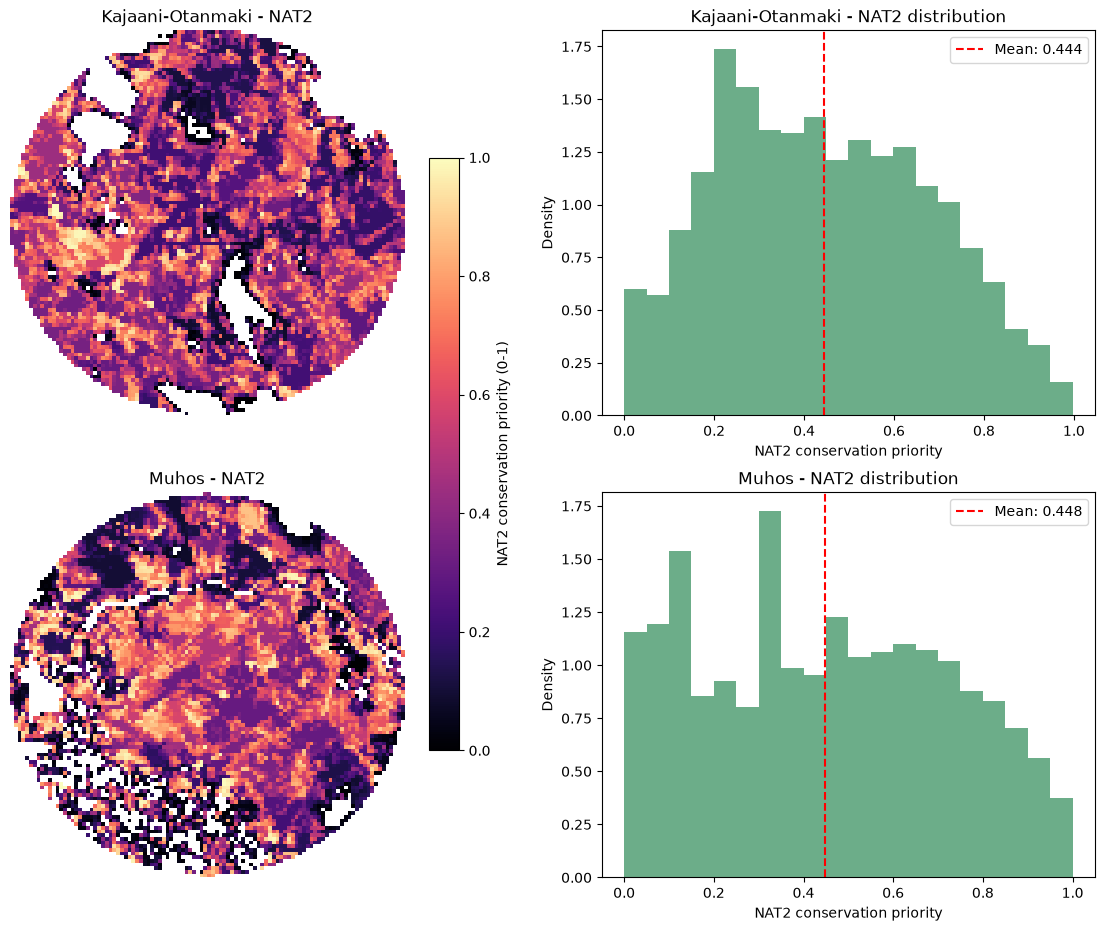

In [33]:
# NAT2 maps and distributions for both study sites

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for i, (site, raster) in enumerate(nat2_maps.items()):

    # Keep valid NAT2 values
    raster = raster.where((raster >= 0) & (raster <= 1))
    values = raster.values
    values = values[np.isfinite(values)]

    # NAT2 map
    im = raster.plot.imshow(
        ax=axes[i, 0],
        cmap="magma",
        vmin=0,
        vmax=1,
        add_colorbar=False
    )

    axes[i, 0].set_title(f"{site} - NAT2")
    axes[i, 0].set_axis_off()

    # NAT2 histogram
    axes[i, 1].hist(
        values,
        bins=20,
        density=True,
        color="#2E8B57",
        alpha=0.7
    )

    axes[i, 1].axvline(
        values.mean(),
        color="red",
        linestyle="--",
        label=f"Mean: {values.mean():.3f}"
    )

    axes[i, 1].set_title(f"{site} - NAT2 distribution")
    axes[i, 1].set_xlabel("NAT2 conservation priority")
    axes[i, 1].set_ylabel("Density")
    axes[i, 1].legend()

# Shared colorbar
fig.colorbar(
    im,
    ax=axes[:, 0].tolist(),
    label="NAT2 conservation priority (0-1)",
    shrink=0.7
)

plt.savefig(
    output_folder / "nat2_maps_distributions.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


,Site,Mean,Median,NAT2 >= 0.75 (%),NAT2 >= 0.90 (%)
0,Kajaani-Otanmaki,0.44,0.44,11.44,2.38
1,Muhos,0.45,0.44,16.74,4.67


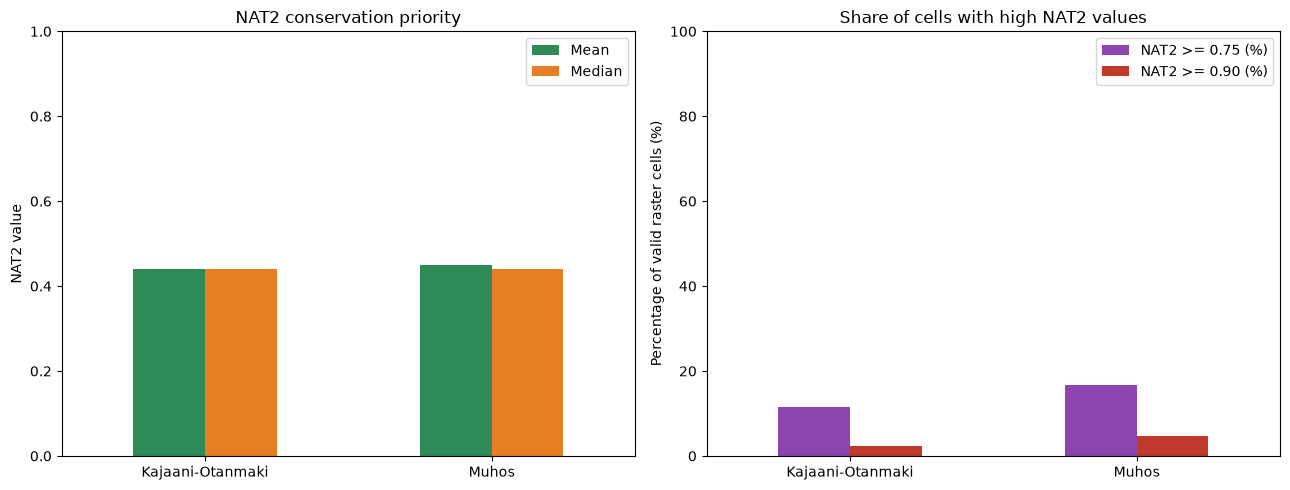

In [74]:
# Compare NAT2 values between study sites

results = []

for site, raster in nat2_maps.items():

    values = raster.values
    values = values[np.isfinite(values)]
    values = values[(values >= 0) & (values <= 1)]

    results.append({
        "Site": site,
        "Mean": values.mean(),
        "Median": np.median(values),
        "NAT2 >= 0.75 (%)": (values >= 0.75).mean() * 100,
        "NAT2 >= 0.90 (%)": (values >= 0.90).mean() * 100
    })

comparison = pd.DataFrame(results).round(2)
display(comparison)

# Create comparison charts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Mean and median NAT2
comparison.plot(
    x="Site",
    y=["Mean", "Median"],
    kind="bar",
    ax=axes[0],
    color=["#2E8B57", "#E67E22"]
)

axes[0].set_title("NAT2 conservation priority")
axes[0].set_ylabel("NAT2 value")
axes[0].set_xlabel("")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

# Share of cells with high NAT2 values
comparison.plot(
    x="Site",
    y=["NAT2 >= 0.75 (%)", "NAT2 >= 0.90 (%)"],
    kind="bar",
    ax=axes[1],
    color=["#8E44AD", "#C0392B"]
)

axes[1].set_title("Share of cells with high NAT2 values")
axes[1].set_ylabel("Percentage of valid raster cells (%)")
axes[1].set_xlabel("")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(
    output_folder / "nat2_summary_chart.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


### Results and Interpretation

The NAT2 analysis revealed considerable variation in forest conservation priority within the 5 km buffers around both study sites. Mean values were similar in Kajaani–Otanmäki (0.444) and Muhos (0.448), but both landscapes contained areas with relatively high NAT2 values.

In Kajaani–Otanmäki, 11.44% of valid raster cells had NAT2 values ≥ 0.75, compared with 16.74% in Muhos. The proportion of cells with values ≥ 0.90 was 2.38% and 4.67%, respectively.

These results indicate that both landscapes contain forest areas with characteristics associated with higher relative conservation priority, although their distribution is spatially heterogeneous.


### 6. Forest Clearing

Forest clearing took place at both planned Google data centre sites in 2026. According to Yle (14 October 2026), approximately 330 hectares of forest were cleared in Muhos and just under 200 hectares in Kajaani–Otanmäki.

These figures are reported estimates and were not independently calculated in this project (https://yle.fi/a/74-20251367)

In [36]:
# Reported forest clearing at the two sites
# Source: Yle, 14 October 2026

clearing = pd.DataFrame({
    "Site": ["Kajaani-Otanmaki", "Muhos"],
    "Reported forest clearing": ["Just under 200 ha", "About 330 ha"]
})

clearing

,Site,Reported forest clearing
0,Kajaani-Otanmaki,Just under 200 ha
1,Muhos,About 330 ha


## Conclusions

The analysis of GBIF records from 2016–2025 documented several mammal species within the surrounding landscapes. The number of recorded species increased with buffer size, from 8 to 17 species in Kajaani–Otanmäki and from 5 to 24 in Muhos between the 5 km and 25 km buffers. Among the recorded mammals were species of conservation interest, including the Siberian flying squirrel (*Pteromys volans*), Eurasian otter (*Lutra lutra*) and Eurasian lynx (*Lynx lynx*). These observations provide information about species documented in the wider landscapes, although their distribution is influenced by differences in observation effort and data availability.

The spatial analysis also identified Natura 2000 sites near both development locations, with the nearest designated areas located 3.43 km from Kajaani–Otanmäki and 5.66 km from Muhos. These distances describe the conservation context but do not establish ecological impacts on protected areas.

The NAT2 analysis revealed considerable variation in historical forest conservation priority within the 5 km buffers. Although mean NAT2 values were similar between the two study areas, both contained forest cells with relatively high values, reflecting spatial variation in forest characteristics associated with dead-wood potential. 

**Together, these findings highlight why the ecological significance of forest clearing cannot be evaluated from the area removed alone.** The characteristics of the affected forests and their potential importance for wildlife are also relevant considerations.

Overall, the project demonstrates how open geospatial data and Python can contribute to preliminary conservation assessments. A more detailed evaluation would require verified clearing boundaries, more recent forest data and species-specific information on habitat use to assess the ecological consequences of these land-use changes.